# IA102 — Notebook 4 — Améliorer la généralisation

**Durée : 20 minutes** · Objectif visé : **O3** — entraîner des modèles avec PyTorch et suivre leur généralisation

Au notebook 3, le CNN disposait de 60 000 images. Dans de nombreux projets (imagerie médicale, données de recherche), on dispose de **quelques centaines** d'exemples annotés. Ce notebook examine le comportement d'un réseau dans ce contexte et les techniques qui améliorent sa généralisation.

### Plan
1. Diagnostiquer le surapprentissage sur les courbes de perte
2. L'arrêt précoce
3. Le dropout
4. L'augmentation de données
5. Le transfert d'apprentissage

Temps de calcul : environ 2 minutes sur processeur pour les sections 1 à 4, et 2 minutes supplémentaires pour la section 5 ; quelques secondes sur GPU.

In [2]:
# Outil de questions de vérification (exécutez cette cellule sans la modifier)
import ipywidgets as widgets
from IPython.display import display, Markdown

def quiz(question, options, bonne, explication):
    """Affiche une question à choix multiples avec rétroaction immédiate."""
    choix = widgets.RadioButtons(options=options, value=None,
                                 layout={"width": "max-content"})
    bouton = widgets.Button(description="Vérifier", button_style="primary")
    sortie = widgets.Output()

    def verifier(_):
        with sortie:
            sortie.clear_output()
            if choix.value is None:
                display(Markdown("Veuillez choisir une réponse."))
            elif choix.value == options[bonne]:
                display(Markdown(f"**Bonne réponse.** {explication}"))
            else:
                display(Markdown("**Réponse incorrecte.** Relisez la section précédente et essayez de nouveau."))

    bouton.on_click(verifier)
    display(Markdown(f"**Question de vérification.** {question}"), choix, bouton, sortie)

In [ ]:
import os, time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DOSSIER_DONNEES = os.environ.get("IA102_DONNEES", "donnees")
appareil = "cuda" if torch.cuda.is_available() else "cpu"
CLASSES = ["T-shirt/haut", "Pantalon", "Pull", "Robe", "Manteau", "Sandale", "Chemise", "Basket", "Sac", "Bottine"]

# Scénario de données limitées : 500 images d'entraînement tirées au hasard
indices = np.random.default_rng(0).choice(60000, 500, replace=False)
sans_aug = transforms.ToTensor()
petit_ent = Subset(datasets.FashionMNIST(DOSSIER_DONNEES, train=True, download=True, transform=sans_aug), indices)
validation = Subset(datasets.FashionMNIST(DOSSIER_DONNEES, train=False, download=True, transform=sans_aug), range(2000))
charge_val = DataLoader(validation, batch_size=1000)
charge_ent_eval = DataLoader(petit_ent, batch_size=500)    # mesure de la perte d'entraînement, sans augmentation
print(f"Entraînement : {len(petit_ent)} images | Validation : {len(validation)} images | appareil : {appareil}")

100%|██████████| 26.4M/26.4M [00:01<00:00, 19.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 303kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 5.61MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 21.1MB/s]


Entraînement : 500 images | Validation : 2000 images | appareil : cpu


Le CNN utilisé est un peu plus large qu'au notebook 3, avec une option de **dropout** activée plus loin.

### Initialisation du modèle et d'entraînement

L'ensemble des outils nécessaires pour construire, évaluer et entraîner notre modèle de réseau de neurones convolutif (CNN). Voici une décomposition de son rôle :

#### 1. Définition de la classe `CNN(nn.Module)`
Elle configure l'architecture du réseau de neurones qui va analyser les images de vêtements :
* **Deux couches de convolution (`nn.Conv2d`)** suivies de fonctions d'activation **ReLU** et de couches de réduction **MaxPool2d**. Elles servent à extraire les caractéristiques visuelles (bords, formes, textures).
* **`nn.Flatten`** : Cette opération transforme la grille de caractéristiques 2D finale en un vecteur 1D pour pouvoir la passer aux couches denses (fully connected).
* **`nn.Dropout(p_dropout)`** : Une technique de régularisation qui désactive aléatoirement un pourcentage des neurones durant l'entraînement pour éviter que le réseau ne devienne trop dépendant de détails trop spécifiques de l'ensemble d'entraînement.
* **Deux couches linéaires (`nn.Linear`)** : La première projette les caractéristiques vers un espace intermédiaire de 256 neurones, et la seconde produit les 10 scores finaux correspondant aux 10 classes de vêtements.

#### 2. Définition de la fonction de perte (`perte_fn`)
* Elle utilise **`nn.CrossEntropyLoss()`**, qui est la fonction de coût standard pour les problèmes de classification multi-classes. Elle compare les probabilités prédites par le modèle avec les vraies étiquettes.

#### 3. Fonction d'évaluation `evaluer(modele, chargeur)`
* Elle calcule la performance (la perte moyenne et la précision/exactitude) du modèle sur un jeu de données donné (entraînement ou validation).
* Elle bascule temporairement le modèle en mode évaluation (`modele.eval()`) et désactive le calcul des gradients (`with torch.no_grad()`) pour économiser de la mémoire et accélérer le processus.

#### 4. Fonction d'entraînement `entrainer(modele, donnees_ent, n_epoques=45)`
* Elle orchestre l'entraînement du modèle sur plusieurs passages complets des données (époques).
* À chaque époque, elle sépare les données en mini-lots (batches) de taille 64, effectue une passe de prédiction, calcule l'erreur, calcule les gradients (`perte.backward()`), et ajuste les paramètres du réseau avec l'optimiseur **Adam** (`optimiseur.step()`).
* Enfin, elle enregistre l'évolution de la perte d'entraînement et de validation ainsi que l'exactitude à chaque époque dans un dictionnaire `suivi` pour pouvoir tracer les courbes de performance par la suite.

In [ ]:
class CNN(nn.Module):
    def __init__(self, p_dropout=0.0):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Dropout(p_dropout), nn.Linear(64 * 7 * 7, 256), nn.ReLU(),
            nn.Dropout(p_dropout), nn.Linear(256, 10),
        )

    def forward(self, x):
        return self.reseau(x)

perte_fn = nn.CrossEntropyLoss()

def evaluer(modele, chargeur):
    modele.eval(); total, correctes, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in chargeur:
            x, y = x.to(appareil), y.to(appareil)
            sortie = modele(x)
            total += perte_fn(sortie, y).item() * len(y); correctes += (sortie.argmax(1) == y).sum().item(); n += len(y)
    return total / n, correctes / n

def entrainer(modele, donnees_ent, n_epoques=45):
    torch.manual_seed(0)
    modele = modele.to(appareil)
    charge = DataLoader(donnees_ent, batch_size=64, shuffle=True)
    optimiseur = torch.optim.Adam(modele.parameters(), lr=1e-3)
    suivi = {"perte_ent": [], "perte_val": [], "exact_val": []}
    for epoque in range(n_epoques):
        modele.train()
        for x, y in charge:
            x, y = x.to(appareil), y.to(appareil)
            optimiseur.zero_grad(); perte = perte_fn(modele(x), y); perte.backward(); optimiseur.step()
        suivi["perte_ent"].append(evaluer(modele, charge_ent_eval)[0])
        perte_val, exact = evaluer(modele, charge_val)
        suivi["perte_val"].append(perte_val); suivi["exact_val"].append(exact)
    return suivi

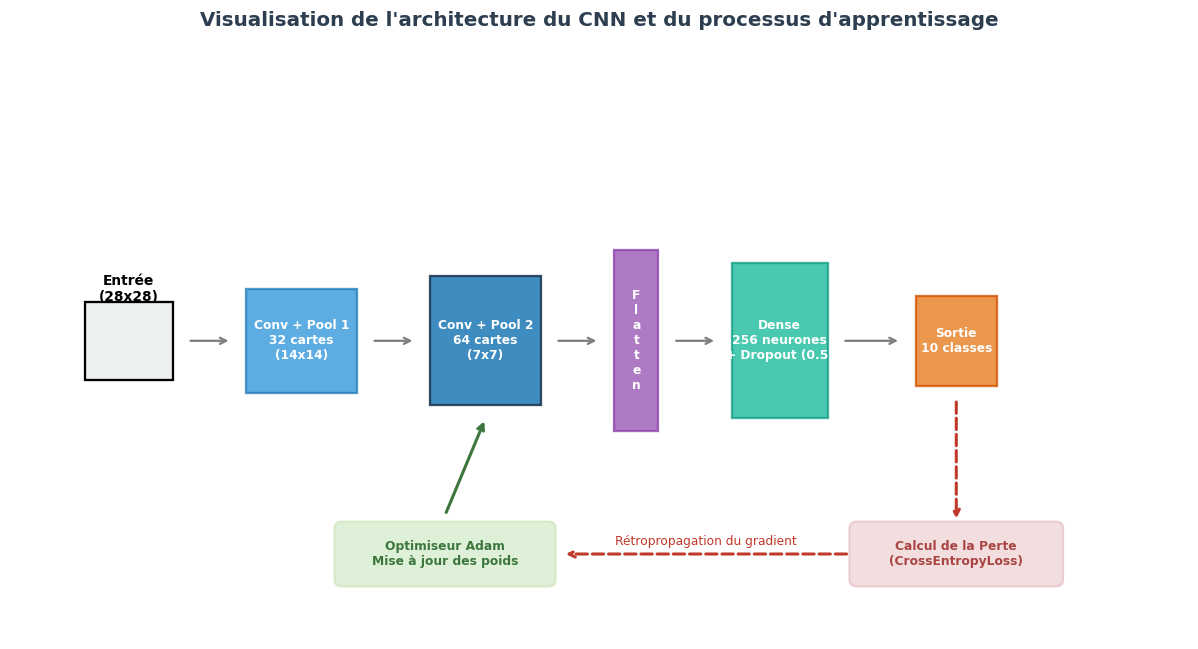

## 1. Diagnostiquer le surapprentissage

**Prédiction.** Avec 500 images et 45 époques, comment évoluent la perte d'entraînement et la perte de validation ?

Durée : 140 s | exactitude de validation finale : 81.2%


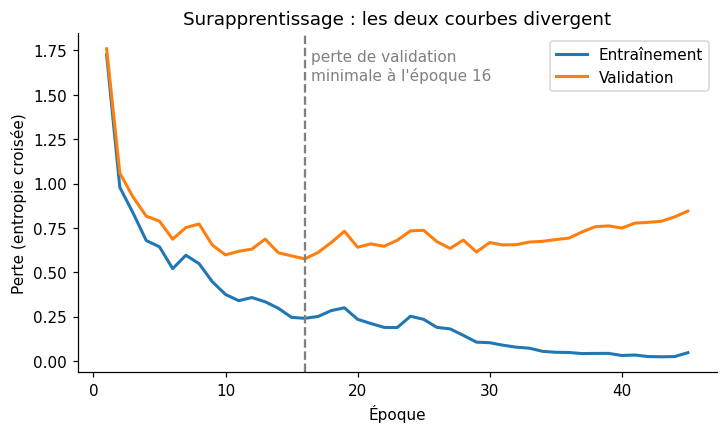

In [ ]:
debut = time.time()
base = entrainer(CNN(p_dropout=0.0), petit_ent)
print(f"Durée : {time.time() - debut:.0f} s | exactitude de validation finale : {base['exact_val'][-1]:.1%}")

meilleure_ep = int(np.argmin(base["perte_val"])) + 1
ep = range(1, len(base["perte_val"]) + 1)
plt.figure(figsize=(7.5, 4))
plt.plot(ep, base["perte_ent"], lw=2, label="Entraînement")
plt.plot(ep, base["perte_val"], lw=2, label="Validation")
plt.axvline(meilleure_ep, color="gray", ls="--")
plt.text(meilleure_ep + 0.5, max(base["perte_val"]) * 0.9, f"perte de validation\nminimale à l'époque {meilleure_ep}", color="gray")
plt.xlabel("Époque"); plt.ylabel("Perte (entropie croisée)"); plt.title("Surapprentissage : les deux courbes divergent")
plt.legend(); plt.show()

- La perte d'**entraînement** tend vers zéro : le réseau mémorise les 500 images.
- La perte de **validation** diminue, puis **augmente** : le réseau devient de plus en plus confiant, y compris dans ses erreurs. C'est la signature du **surapprentissage**.

Un réseau de ce type compte plus de 800 000 paramètres pour 500 exemples : il dispose largement de la capacité nécessaire pour mémoriser l'ensemble d'entraînement.

## 2. L'arrêt précoce

On surveille la perte de validation et l'on conserve les paramètres de l'époque où elle est minimale (ligne pointillée). En pratique, on interrompt l'entraînement après un nombre fixé d'époques sans amélioration (la **patience**).

```python
meilleure_perte, patience, sans_progres = float("inf"), 5, 0
for epoque in range(n_epoques):
    entrainer_une_epoque(...)
    perte_val = evaluer(modele, charge_val)[0]
    if perte_val < meilleure_perte:
        meilleure_perte, sans_progres = perte_val, 0
        torch.save(modele.state_dict(), "meilleur_modele.pt")
    else:
        sans_progres += 1
        if sans_progres >= patience:
            break
```

L'ensemble utilisé pour l'arrêt précoce est un ensemble de **validation**, distinct de l'ensemble de test final.

## 3. Le dropout

À chaque mini-lot, le **dropout** met à zéro une fraction aléatoire $p$ des activations (ici $p = 0{,}5$). Le réseau ne peut plus s'appuyer sur quelques neurones particuliers ; il doit répartir l'information. Cet effet s'apparente à l'entraînement d'un ensemble de sous-réseaux.

Le dropout n'est actif qu'en mode entraînement (`modele.train()`) ; il est désactivé en évaluation (`modele.eval()`), et les activations sont mises à l'échelle en conséquence.

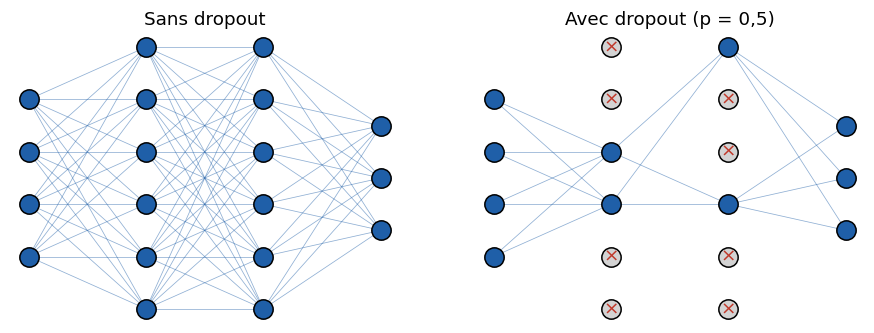

In [ ]:
rng = np.random.default_rng(3)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
couches = [4, 6, 6, 3]
for ax, titre, eteindre in [(axes[0], "Sans dropout", False), (axes[1], "Avec dropout (p = 0,5)", True)]:
    pos = {(c, i): (c * 3, i - n / 2) for c, n in enumerate(couches) for i in range(n)}
    eteints = {k for k in pos if eteindre and 0 < k[0] < len(couches) - 1 and rng.random() < 0.5}
    for (c, i), (x, y) in pos.items():
        if c + 1 < len(couches):
            for j in range(couches[c + 1]):
                if (c, i) not in eteints and (c + 1, j) not in eteints:
                    x2, y2 = pos[(c + 1, j)]; ax.plot([x, x2], [y, y2], color="#1f5fa8", lw=0.5, alpha=0.5)
    for k, (x, y) in pos.items():
        ax.scatter(x, y, s=160, color="lightgray" if k in eteints else "#1f5fa8", edgecolor="k", zorder=3)
        if k in eteints: ax.text(x, y, "×", ha="center", va="center", fontsize=12, color="#c0392b", zorder=4)
    ax.set_title(titre); ax.axis("off")
plt.show()

## 4. L'augmentation de données

On génère à la volée des **variantes** de chaque image d'entraînement (symétrie horizontale, léger décalage). Le réseau voit une version légèrement différente de chaque image à chaque époque, ce qui limite la mémorisation.

Les transformations doivent **préserver l'étiquette** : une symétrie horizontale ne change pas la nature d'un vêtement, mais elle changerait un « 6 » manuscrit ou l'orientation anatomique d'une radiographie.

In [ ]:
apercu = transforms.Compose([transforms.RandomHorizontalFlip(), transforms.RandomAffine(degrees=0, translate=(0.08, 0.08))])
originale, lab = datasets.FashionMNIST(DOSSIER_DONNEES, train=True)[indices[0]]
torch.manual_seed(1)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.9))
axes[0].imshow(originale, cmap="gray_r"); axes[0].set_title("Originale", fontsize=9)
for ax in axes[1:]:
    ax.imshow(apercu(originale), cmap="gray_r"); ax.set_title("Variante", fontsize=9)
for ax in axes: ax.axis("off")
plt.suptitle(f"Variantes générées d'une même image ({CLASSES[lab]})", y=1.08); plt.show()

### Exercice 9 — Combiner dropout et augmentation de données

1. Complétez la chaîne de transformations : symétrie horizontale aléatoire, décalage aléatoire de 8 %, conversion en tenseur.
2. Entraînez un CNN avec un dropout de 0,5 sur ces données augmentées.

In [ ]:
transformation_aug = transforms.Compose([
    ...,   # À COMPLÉTER : symétrie horizontale aléatoire   transforms.RandomHorizontalFlip()
    ...,   # À COMPLÉTER : transforms.RandomAffine(degrees=0, translate=(0.08, 0.08))
    ...,   # À COMPLÉTER : conversion en tenseur transforms.ToTensor(),
])
petit_ent_aug = Subset(datasets.FashionMNIST(DOSSIER_DONNEES, train=True, transform=transformation_aug), indices)

debut = time.time()
regularise = entrainer(CNN(p_dropout=...), petit_ent_aug)   # À COMPLÉTER
print(f"Durée : {time.time() - debut:.0f} s")

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
transformation_aug = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(degrees=0, translate=(0.08, 0.08)),
    transforms.ToTensor(),
])
petit_ent_aug = Subset(datasets.FashionMNIST(DOSSIER_DONNEES, train=True, transform=transformation_aug), indices)

debut = time.time()
regularise = entrainer(CNN(p_dropout=0.5), petit_ent_aug)
print(f"Durée : {time.time() - debut:.0f} s")
```

</details>

In [ ]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
for suivi, nom, c in [(base, "Sans régularisation", "#c0392b"), (regularise, "Dropout et augmentation", "#1e8449")]:
    a.plot(ep, suivi["perte_ent"], color=c, ls=":", lw=1.5, label=f"{nom} : entraînement")
    a.plot(ep, suivi["perte_val"], color=c, lw=2.5, label=f"{nom} : validation")
    b.plot(ep, suivi["exact_val"], color=c, lw=2.5, label=nom)
a.set_xlabel("Époque"); a.set_ylabel("Perte"); a.set_title("La régularisation empêche la remontée de la perte"); a.legend(fontsize=8)
b.set_xlabel("Époque"); b.set_ylabel("Exactitude de validation"); b.set_title("Exactitude de validation"); b.legend(fontsize=8)
plt.tight_layout(); plt.show()

for suivi, nom in [(base, "Sans régularisation"), (regularise, "Dropout et augmentation")]:
    ecart = suivi["perte_val"][-1] - suivi["perte_ent"][-1]
    print(f"{nom:<25} perte de validation finale {suivi['perte_val'][-1]:.3f} | écart validation − entraînement {ecart:.3f} | "
          f"exactitude {suivi['exact_val'][-1]:.1%}")

**Interprétation.** Avec la régularisation, la perte de validation ne remonte plus et l'écart avec l'entraînement est divisé par plus de trois : le modèle généralise mieux et ses probabilités sont mieux calibrées. L'exactitude reste en revanche du même ordre : le modèle régularisé apprend plus lentement, et surtout, 500 images contiennent une information limitée. Avec 60 000 images, le même type de réseau dépassait 89 % (notebook 3).

Lorsque collecter davantage de données est impossible, on peut **réutiliser la connaissance** d'un réseau entraîné sur un très grand corpus.

## 5. Le transfert d'apprentissage

**ResNet18** a été entraîné sur **ImageNet** (1,2 million de photographies, 1000 catégories). Ses premières couches détectent des contours, des textures et des formes : des caractéristiques utiles pour la plupart des images naturelles.

On réutilise ce réseau en **gelant** ses paramètres et en **remplaçant uniquement la dernière couche** par une couche adaptée à la nouvelle tâche.

```
ResNet18 préentraîné (11,7 M de paramètres, gelés)          Nouvelle tête (entraînée)
[Conv -> ... -> Conv -> moyenne globale]  -> 512 caractéristiques ->  Linear(512, 10)
```

**Tâche :** classer des photographies couleur de **CIFAR-10** (avion, voiture, oiseau, chat, etc.) avec seulement **100 images par classe**.

Cette section requiert les poids de ResNet18 (45 Mo) et CIFAR-10 (170 Mo). Sur une grappe de l'Alliance, exécutez d'abord `preparer_donnees.py` sur un **nœud de connexion**.

In [5]:
from torchvision.models import resnet18, ResNet18_Weights

CLASSES_CIFAR = ["avion", "voiture", "oiseau", "chat", "cerf", "chien", "grenouille", "cheval", "bateau", "camion"]
try:
    poids = ResNet18_Weights.DEFAULT
    resnet = resnet18(weights=poids)
    pretraitement = poids.transforms()          # redimensionnement à 224 × 224 et normalisation d'ImageNet
    cifar_ent = datasets.CIFAR10(DOSSIER_DONNEES, train=True, download=True, transform=pretraitement)
    cifar_test = datasets.CIFAR10(DOSSIER_DONNEES, train=False, download=True, transform=pretraitement)
    cibles = np.array(cifar_ent.targets)
    idx_ent = np.concatenate([np.random.default_rng(0).choice(np.where(cibles == c)[0], 100, replace=False) for c in range(10)])
    cifar_petit = Subset(cifar_ent, idx_ent)
    cifar_test_petit = Subset(cifar_test, range(1000))
    TRANSFERT_DISPONIBLE = True
    print(f"ResNet18 chargé : {sum(p.numel() for p in resnet.parameters()) / 1e6:.1f} millions de paramètres")
    print(f"CIFAR-10 : {len(cifar_petit)} images d'entraînement, {len(cifar_test_petit)} images de test")
except Exception as erreur:
    TRANSFERT_DISPONIBLE = False
    print("Poids de ResNet18 ou CIFAR-10 indisponibles :", type(erreur).__name__)
    print("Exécutez preparer_donnees.py sur une machine connectée à Internet, puis relancez cette cellule.")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 198MB/s]

Poids de ResNet18 ou CIFAR-10 indisponibles : NameError
Exécutez preparer_donnees.py sur une machine connectée à Internet, puis relancez cette cellule.


### Exercice 10 — Geler le réseau et remplacer sa tête

1. Gelez tous les paramètres de `resnet` (`p.requires_grad = False`).
2. Remplacez la dernière couche `resnet.fc` par `nn.Identity()` : le réseau renvoie alors ses 512 caractéristiques.
3. Créez la nouvelle tête : une couche linéaire de 512 vers 10 classes.

In [ ]:
if TRANSFERT_DISPONIBLE:
    for p in resnet.parameters():
        ...                          # À COMPLÉTER True or False?
    resnet.fc = ...                  # À COMPLÉTER nn.Identity()
    tete = ...                       # À COMPLÉTER nn.Linear(..., ...)
    print("Paramètres entraînables :", sum(p.numel() for p in tete.parameters()))

<details>
<summary><b>Afficher la solution</b> (après avoir fait l'exercice)</summary>

```python
if TRANSFERT_DISPONIBLE:
    for p in resnet.parameters():
        p.requires_grad = False
    resnet.fc = nn.Identity()
    tete = nn.Linear(512, 10)
    print("Paramètres entraînables :", sum(p.numel() for p in tete.parameters()))
```

</details>

Le tronc étant gelé, ses sorties ne changent pas d'une époque à l'autre. On calcule donc les caractéristiques **une seule fois**, puis on entraîne la tête sur ces caractéristiques : l'entraînement est presque instantané.

In [ ]:
def extraire_caracteristiques(reseau, donnees):
    reseau = reseau.to(appareil).eval()
    sorties, etiquettes = [], []
    with torch.no_grad():
        for x, y in DataLoader(donnees, batch_size=100):
            sorties.append(reseau(x.to(appareil)).cpu()); etiquettes.append(y)
    return torch.cat(sorties), torch.cat(etiquettes)

if TRANSFERT_DISPONIBLE:
    debut = time.time()
    car_ent, y_ent = extraire_caracteristiques(resnet, cifar_petit)
    car_test, y_test = extraire_caracteristiques(resnet, cifar_test_petit)
    print(f"Caractéristiques : {tuple(car_ent.shape)} | calculées en {time.time() - debut:.0f} s")

    torch.manual_seed(0)
    optimiseur = torch.optim.Adam(tete.parameters(), lr=1e-3)
    for epoque in range(100):
        optimiseur.zero_grad(); perte = perte_fn(tete(car_ent), y_ent); perte.backward(); optimiseur.step()
    with torch.no_grad():
        exact_transfert = (tete(car_test).argmax(1) == y_test).float().mean().item()
    print(f"Transfert d'apprentissage (ResNet18 gelé, nouvelle tête) : {exact_transfert:.1%}")

Comparaison avec un CNN entraîné **à partir de zéro** sur les mêmes 1000 images :

In [ ]:
if TRANSFERT_DISPONIBLE:
    brut = transforms.ToTensor()
    cifar_brut_ent = Subset(datasets.CIFAR10(DOSSIER_DONNEES, train=True, transform=brut), idx_ent)
    cifar_brut_test = Subset(datasets.CIFAR10(DOSSIER_DONNEES, train=False, transform=brut), range(1000))
    torch.manual_seed(0)
    zero = nn.Sequential(
        nn.Conv2d(3, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Dropout(0.5), nn.Linear(64 * 8 * 8, 256), nn.ReLU(), nn.Linear(256, 10)).to(appareil)
    opt_zero = torch.optim.Adam(zero.parameters(), lr=1e-3)
    for epoque in range(30):
        zero.train()
        for x, y in DataLoader(cifar_brut_ent, batch_size=64, shuffle=True):
            x, y = x.to(appareil), y.to(appareil)
            opt_zero.zero_grad(); perte_fn(zero(x), y).backward(); opt_zero.step()
    _, exact_zero = evaluer(zero, DataLoader(cifar_brut_test, batch_size=500))
    print(f"CNN entraîné à partir de zéro : {exact_zero:.1%}")
    print(f"Transfert d'apprentissage     : {exact_transfert:.1%}")
    print("Hasard (10 classes)           : 10,0 %")

Avec exactement les mêmes 1000 images, le réseau préentraîné dépasse nettement le CNN entraîné à partir de zéro : il réutilise des caractéristiques visuelles apprises sur 1,2 million d'images. Le transfert d'apprentissage est la pratique standard dans la plupart des projets appliqués, y compris en imagerie médicale.

Étape suivante possible : le **réglage fin** (*fine-tuning*), qui consiste à dégeler les dernières couches et à les réentraîner avec un petit taux d'apprentissage. C'est le principe utilisé pour adapter les grands modèles de langage (notebook bonus).

In [ ]:
quiz("La perte d'entraînement diminue toujours, mais la perte de validation augmente depuis 10 époques. Que faire ?",
     ["Poursuivre l'entraînement", "Revenir au meilleur modèle (arrêt précoce) et régulariser", "Augmenter le taux d'apprentissage"],
     1, "C'est la signature du surapprentissage : arrêt précoce, dropout, augmentation de données.")

In [ ]:
quiz("Dans le transfert d'apprentissage avec un tronc gelé, quels paramètres sont entraînés ?",
     ["Tous les paramètres", "Uniquement ceux de la nouvelle tête", "Aucun"],
     1, "Le tronc préentraîné sert d'extracteur de caractéristiques ; seule la tête adaptée à la tâche est entraînée.")

## À retenir

| Technique | Effet | Mise en œuvre |
| --- | --- | --- |
| Arrêt précoce | Conserve le modèle au minimum de la perte de validation | Surveillance de la validation, patience |
| Dropout | Empêche la dépendance à quelques neurones | `nn.Dropout(p)` |
| Augmentation de données | Multiplie les exemples en préservant l'étiquette | `transforms.RandomHorizontalFlip()`, `RandomAffine` |
| Transfert d'apprentissage | Réutilise des caractéristiques apprises sur un grand corpus | `resnet18(weights=...)`, tronc gelé, nouvelle tête |
| Davantage de données | Le levier le plus efficace | Collecte, annotation, partage |

**Notebook suivant :** 5 — Introduction à l'entraînement haute performance.